# v47 — 潜在モード HMM(datum枝の確率的分類)

回帰(soft凸結合)は bimodal を平均して 6.4 で頭打ち。→ **候補21を K=3 の datum枝(下/中/上=各7候補)に分割**し、
各位置で **どの枝か** を **sticky な線形鎖CRF(=HMM)** で確率分類する。soft凸結合ではなく **分類 + 確率 + 少数状態**。

- **モード代表** `mode_rep[t,k]` = 枝内候補の平均(=その枝の予測TVT)。**枝を当てられれば oracle 3.55**(K=3)。
- **emission**: Encoder が各位置で各枝の証拠(枝のGR整合・struct一致・std等)から枝スコアを出す。
- **遷移**: 対角初期化の **sticky**(枝はめったに乗り換えない)+ 連続性 |mode_rep差|。forward-backward で **P(枝|全証拠)**。
- 予測: 確信区間は枝に commit(分類)、曖昧は確率で hedge。学習=gold枝NLL + soft-MSE。推論=soft周辺 / Viterbi 両方。
学習/推論は `v47/artifacts_v47/` のみ参照。


In [1]:
# ===== 設定 =====
import os, json, time, math, gc
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import GroupKFold
ART=Path(r"C:\Users\kosaka256\Documents\rogii_claude")/"v47"/"artifacts_v47"
NPZ=ART/"candidates_v47.npz"; META=json.loads((ART/"candidates_v47_meta.json").read_text(encoding="utf-8"))
assert NPZ.exists(),"先に build_candidates_v47.py"
K=int(os.environ.get("V47_K","7")); assert 21%K==0; KT=21//K       # 各枝の候補数
STRIDE=16; T_MAX=int(os.environ.get("V47_TMAX","256")); SCALE,SG=30.0,20.0; N_SPLITS=5
D_MODEL,N_LAYER,N_HEAD,D_FF,DROP=128,3,8,256,0.1; LAM_SOFT=0.3; STICKY=2.0
EPOCHS=int(os.environ.get("V47_EPOCHS","40")); BATCH=int(os.environ.get("V47_BATCH","16")); LR=3e-4
NWD=int(os.environ.get("V47_NWELLS","0")); USE_AMP=torch.cuda.is_available()
DEV="cuda" if torch.cuda.is_available() else "cpu"; torch.manual_seed(42); np.random.seed(42)
try: torch.cuda.set_per_process_memory_fraction(0.85)
except Exception: pass
NC=len(META["cand_names"])
print("device",DEV,"| K枝",K,"各",KT,"候補 | T_MAX",T_MAX)


device cuda | K枝 7 各 3 候補 | T_MAX 256


In [7]:
# ===== ロード =====
z=np.load(NPZ); DEL=z["DEL"]; y=z["y"]; lk=z["lk"].astype(np.float64); mds=z["mds"].astype(np.float64); g=z["wellcode"].astype(np.int64); N=len(y)
STD=z["STD"]; CTX=z["ctx"]; GRC=z["GRC"]; GRC2=z["GRC2"]; STRD=z["STRD"]; STRS=z["STRS"]
# 天井: K枝 oracle-mode(枝を当てられたときのRMSE)
_args=np.argsort(DEL,1); _ds=np.take_along_axis(DEL,_args,1).reshape(N,K,KT); _rep=_ds.mean(2)
orc_mode=float(np.sqrt(np.mean(np.min(np.abs(_rep-y[:,None]),1)**2)))
print(f"mean候補={np.sqrt(np.mean((DEL.mean(1)-y)**2)):.4f}  K={K} oracle-mode(天井)={orc_mode:.4f}  mode_rep単体最良={min(np.sqrt(np.mean((_rep[:,k]-y)**2)) for k in range(K)):.4f}")


mean候補=7.3053  K=7 oracle-mode(天井)=2.7236  mode_rep単体最良=7.0676


In [8]:
# ===== bin化→固定長チャンク + モード特徴(枝ごとの代表/証拠) =====
order=np.lexsort((mds,g)); gg=g[order]; _,fst=np.unique(gg,return_index=True); fst=np.sort(fst); bnd=list(fst)+[N]
wells=[int(gg[bnd[k]]) for k in range(len(bnd)-1)]
if NWD>0: wells=wells[:NWD]; bnd=bnd[:NWD+1]
DELo=DEL[order]; STDo=STD[order]; yo=y[order]; CTXo=CTX[order]; GRCo=GRC[order]; GRC2o=GRC2[order]; STRDo=STRD[order]; STRSo=STRS[order]; pos_g=order.copy()
def bmean(a,bid,nb):
    o=np.zeros((nb,)+a.shape[1:],np.float32); c=np.zeros(nb,np.float32); np.add.at(o,bid,a); np.add.at(c,bid,1.0)
    return o/np.maximum(c.reshape((nb,)+(1,)*(a.ndim-1)),1.0), c
def modefeat(d,st,gc1,gc2):     # 各[nb,21] -> 枝集約[nb,K,*]
    a=np.argsort(d,1)
    ds=np.take_along_axis(d,a,1).reshape(-1,K,KT); rep=ds.mean(2); spread=ds.std(2)
    gcs=np.take_along_axis(gc1,a,1).reshape(-1,K,KT).mean(2); gc2s=np.take_along_axis(gc2,a,1).reshape(-1,K,KT).mean(2)
    sts=np.take_along_axis(st,a,1).reshape(-1,K,KT).mean(2)
    return rep.astype(np.float32),spread.astype(np.float32),gcs.astype(np.float32),gc2s.astype(np.float32),sts.astype(np.float32)
def build(s,e):
    n=e-s; nb=(n+STRIDE-1)//STRIDE; bid=np.arange(n)//STRIDE
    d,cnt=bmean(DELo[s:e],bid,nb); st,_=bmean(STDo[s:e],bid,nb); yb,_=bmean(yo[s:e],bid,nb)
    gc1,_=bmean(GRCo[s:e],bid,nb); gc2,_=bmean(GRC2o[s:e],bid,nb)
    strd,_=bmean(STRDo[s:e][:,None],bid,nb); strs,_=bmean(STRSo[s:e][:,None],bid,nb); cx,_=bmean(CTXo[s:e],bid,nb)
    rep,spread,gcs,gc2s,sts=modefeat(d,st,gc1,gc2)                    # [nb,K]
    vs=rep-strd                                                       # 枝-struct
    ctxb=np.repeat(np.stack([np.log1p(np.maximum(cx[:,0],0)),cx[:,1],np.log1p(np.maximum(cx[:,2],0)),strd[:,0]/SCALE,np.log1p(np.maximum(strs[:,0],0))],1)[:,None,:],K,1)
    perm=np.stack([rep/SCALE,gcs/SG,gc2s/SG,np.log1p(np.maximum(sts,0)),spread/SCALE,vs/SCALE],2)   # [nb,K,6]
    feat=np.concatenate([perm,ctxb],2).reshape(nb,-1).astype(np.float32)   # [nb, K*11]
    return feat, rep.astype(np.float32), yb.astype(np.float32), cnt.astype(np.float32), bid
SEQ=[]; CHW=[]
for k in range(len(wells)):
    s,e=bnd[k],bnd[k+1]; feat,rep,yb,cnt,bid=build(s,e); nb=len(rep); pos=pos_g[s:e]
    for c0 in range(0,nb,T_MAX):
        c1=min(c0+T_MAX,nb); rows=np.where((bid>=c0)&(bid<c1))[0]
        SEQ.append(dict(feat=feat[c0:c1],rep=rep[c0:c1],ybin=yb[c0:c1],cnt=cnt[c0:c1],bid=(bid[rows]-c0),pos=pos[rows]))
        CHW.append(wells[k])
FEATD=SEQ[0]["feat"].shape[1]; CHW=np.array(CHW); LEN=np.array([len(s["rep"]) for s in SEQ])
del DELo,STDo,yo,CTXo,GRCo,GRC2o,STRDo,STRSo,STD,CTX,GRC,GRC2,STRS; gc.collect()
print(f"チャンク {len(SEQ)} | emission特徴 {FEATD} | 最大bin {max(len(s['rep']) for s in SEQ)}")


チャンク 1357 | emission特徴 77 | 最大bin 256


In [9]:
# ===== Encoder(1軸) + sticky CRF over K枝 =====
class PE(nn.Module):
    def __init__(s,d,m=2048):
        super().__init__(); pe=torch.zeros(m,d); p=torch.arange(m).unsqueeze(1).float(); dv=torch.exp(torch.arange(0,d,2).float()*(-math.log(10000.)/d)); pe[:,0::2]=torch.sin(p*dv); pe[:,1::2]=torch.cos(p*dv); s.register_buffer("pe",pe)
    def forward(s,T): return s.pe[:T]
class Enc(nn.Module):
    def __init__(s,fc,nk,d=D_MODEL,L=N_LAYER,h=N_HEAD,ff=D_FF,dr=DROP):
        super().__init__(); s.pr=nn.Sequential(nn.Linear(fc,d),nn.GELU(),nn.LayerNorm(d)); s.pe=PE(d); e=nn.TransformerEncoderLayer(d,h,ff,dr,batch_first=True,norm_first=True); s.en=nn.TransformerEncoder(e,L); s.em=nn.Linear(d,nk)
    def forward(s,feat,pad): x=s.pr(feat)+s.pe(feat.size(1)).to(feat.device)[None]; return s.em(s.en(x,src_key_padding_mask=pad))
class StickyCRF(nn.Module):
    def __init__(s,nk):
        super().__init__(); s.nk=nk; s.tr=nn.Parameter(STICKY*torch.eye(nk)); s.g=nn.Parameter(torch.tensor(0.)); s.st=nn.Parameter(torch.zeros(nk)); s.en=nn.Parameter(torch.zeros(nk))
    def _t(s,rep,t): return s.tr[None]-F.softplus(s.g)*(rep[:,t][:,None,:]-rep[:,t-1][:,:,None]).abs()/30.
    def nll(s,em,rep,mask,tags):
        B,T,C=em.shape; a=s.st[None]+em[:,0]; sc=s.st[tags[:,0]]+em[torch.arange(B),0,tags[:,0]]
        for t in range(1,T):
            tr=s._t(rep,t); a=torch.where(mask[:,t][:,None].bool(),em[:,t]+torch.logsumexp(a[:,:,None]+tr,1),a)
            step=em[torch.arange(B),t,tags[:,t]]+tr[torch.arange(B),tags[:,t-1],tags[:,t]]; sc=sc+torch.where(mask[:,t].bool(),step,torch.zeros_like(step))
        return (torch.logsumexp(a+s.en[None],1)-(sc+s.en[tags[torch.arange(B),(mask.sum(1)-1).long()]])).mean()
    def marg(s,em,rep,mask):
        B,T,C=em.shape; al=[s.st[None]+em[:,0]]
        for t in range(1,T): tr=s._t(rep,t); al.append(torch.where(mask[:,t][:,None].bool(),em[:,t]+torch.logsumexp(al[-1][:,:,None]+tr,1),al[-1]))
        be=[None]*T; be[T-1]=s.en[None].expand(B,C).clone()
        for t in range(T-2,-1,-1): tr=s._t(rep,t+1); be[t]=torch.where(mask[:,t+1][:,None].bool(),torch.logsumexp(tr+em[:,t+1][:,None,:]+be[t+1][:,None,:],2),be[t+1])
        return torch.softmax(torch.stack(al,1)+torch.stack(be,1),2)
    def viterbi(s,em,rep,mask):
        B,T,C=em.shape; sc=s.st[None]+em[:,0]; bps=[]; ident=torch.arange(C,device=em.device)[None].expand(B,C)
        for t in range(1,T):
            tr=s._t(rep,t); best,arg=(sc[:,:,None]+tr).max(1); up=mask[:,t][:,None].bool(); sc=torch.where(up,em[:,t]+best,sc); bps.append(torch.where(up,arg,ident))
        bps=torch.stack(bps,1) if bps else torch.zeros(B,0,C,dtype=torch.long,device=em.device); last=(mask.sum(1)-1).long(); path=torch.zeros(B,T,dtype=torch.long,device=em.device); cur=(sc+s.en[None]).argmax(1)
        for b in range(B):
            L=int(last[b].item()); st=int(cur[b].item()); path[b,L]=st
            for t in range(L,0,-1): st=int(bps[b,t-1,st].item()); path[b,t-1]=st
        return path
print("Encoder params ~", round(sum(p.numel() for p in Enc(FEATD,K).parameters())/1e6,2),"M")


Encoder params ~ 0.41 M


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\2669217068.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  super().__init__(); s.pr=nn.Sequential(nn.Linear(fc,d),nn.GELU(),nn.LayerNorm(d)); s.pe=PE(d); e=nn.TransformerEncoderLayer(d,h,ff,dr,batch_first=True,norm_first=True); s.en=nn.TransformerEncoder(e,L); s.em=nn.Linear(d,nk)


In [10]:
# ===== 学習(gold枝NLL + soft-MSE) → 行レベルOOF(soft周辺 / Viterbi) =====
def col(bt):
    T=max(len(b["rep"]) for b in bt); B=len(bt); feat=torch.zeros(B,T,FEATD); rep=torch.zeros(B,T,K); ybin=torch.zeros(B,T); mask=torch.zeros(B,T)
    for i,b in enumerate(bt):
        t=len(b["rep"]); feat[i,:t]=torch.from_numpy(b["feat"]); rep[i,:t]=torch.from_numpy(b["rep"]); ybin[i,:t]=torch.from_numpy(b["ybin"]); mask[i,:t]=1.
    return feat,rep,ybin,mask
def batches(idxs): idxs=sorted(idxs,key=lambda i:LEN[i]); return [idxs[c0:c0+BATCH] for c0 in range(0,len(idxs),BATCH)]
folds=list(GroupKFold(N_SPLITS).split(np.arange(len(SEQ)),groups=CHW)); oof=np.full(N,np.nan,np.float32); oof_v=np.full(N,np.nan,np.float32)
def row_reps(pos):
    Dr=DEL[pos]; a=np.argsort(Dr,1); ds=np.take_along_axis(Dr,a,1).reshape(len(pos),K,KT); return ds.mean(2)   # [nr,K]
def fill(enc,crf,idxs):
    enc.eval(); crf.eval()
    with torch.no_grad():
        for bt in batches(idxs):
            sub=[SEQ[i] for i in bt]; feat,rep,ybin,mask=[t.to(DEV) for t in col(sub)]
            with torch.autocast("cuda",enabled=USE_AMP): em=enc(feat,mask==0)
            em=em.float(); P=crf.marg(em,rep,mask).cpu().numpy(); path=crf.viterbi(em,rep,mask).cpu().numpy()
            for bi,b in enumerate(sub):
                rr=row_reps(b["pos"]); Pr=P[bi][b["bid"]]; oof[b["pos"]]=(Pr*rr).sum(1).astype(np.float32)
                pr=path[bi][b["bid"]]; oof_v[b["pos"]]=rr[np.arange(len(pr)),pr].astype(np.float32)
t0=time.time()
for k,(tr,va) in enumerate(folds):
    enc=Enc(FEATD,K).to(DEV); crf=StickyCRF(K).to(DEV); opt=torch.optim.AdamW(list(enc.parameters())+list(crf.parameters()),lr=LR,weight_decay=1e-4); scaler=torch.cuda.amp.GradScaler(enabled=USE_AMP)
    trb=batches(list(tr)); sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=EPOCHS*max(1,len(trb))); best=1e9; pat=0; fe=ART/f"mode_enc{k}.pt"; fc=ART/f"mode_crf{k}.pt"
    for ep in range(EPOCHS):
        enc.train(); crf.train(); np.random.shuffle(trb); tl=0.0; nb=0
        for bt in trb:
            sub=[SEQ[i] for i in bt]; feat,rep,ybin,mask=[t.to(DEV) for t in col(sub)]; gold=(rep-ybin.unsqueeze(-1)).abs().argmin(-1)
            with torch.autocast("cuda",enabled=USE_AMP): em=enc(feat,mask==0)
            em=em.float(); P=crf.marg(em,rep,mask); soft=(P*rep).sum(-1); mse=(((soft-ybin)**2)*mask).sum()/mask.sum().clamp_min(1.); loss=crf.nll(em,rep,mask,gold)+LAM_SOFT*mse
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(list(enc.parameters())+list(crf.parameters()),1.); scaler.step(opt); scaler.update(); sch.step(); tl+=float(mse); nb+=1
        enc.eval(); crf.eval(); vs=0.0; vn=0
        with torch.no_grad():
            for bt in batches(list(va)):
                sub=[SEQ[i] for i in bt]; feat,rep,ybin,mask=[t.to(DEV) for t in col(sub)]
                with torch.autocast("cuda",enabled=USE_AMP): em=enc(feat,mask==0)
                P=crf.marg(em.float(),rep,mask); soft=(P*rep).sum(-1); vs+=float((((soft-ybin)**2)*mask).sum()/mask.sum().clamp_min(1.))*len(sub); vn+=len(sub)
        vrm=math.sqrt(vs/max(vn,1))
        if vrm<best-1e-4: best=vrm; pat=0; torch.save(enc.state_dict(),fe); torch.save(crf.state_dict(),fc)
        else: pat+=1
        if ep%5==0 or ep==EPOCHS-1: print(f" fold{k} ep{ep} soft_train={math.sqrt(tl/max(nb,1)):.4f} soft_val={vrm:.4f}{' *' if pat==0 else ''} ({time.time()-t0:.0f}s)",flush=True)
        if pat>=8: print(f" fold{k} early stop ep{ep}"); break
    enc.load_state_dict(torch.load(fe)); crf.load_state_dict(torch.load(fc)); fill(enc,crf,list(va))
    print(f"== fold{k} OOF埋め {np.mean(np.isfinite(oof))*100:.1f}%"); del enc,crf,opt,scaler; gc.collect(); torch.cuda.empty_cache() if DEV=="cuda" else None
np.save(ART/"oof_mode_soft.npy",oof); np.save(ART/"oof_mode_viterbi.npy",oof_v); print("OOF saved.")


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\2669217068.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  super().__init__(); s.pr=nn.Sequential(nn.Linear(fc,d),nn.GELU(),nn.LayerNorm(d)); s.pe=PE(d); e=nn.TransformerEncoderLayer(d,h,ff,dr,batch_first=True,norm_first=True); s.en=nn.TransformerEncoder(e,L); s.em=nn.Linear(d,nk)
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\4150559791.py:23: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  enc=Enc(FEATD,K).to(DEV); crf=StickyCRF(K).to(DEV); opt=torch.optim.AdamW(list(enc.parameters())+list(crf.parameters()),lr=LR,weight_decay=1e-4); scaler=torch.cuda.amp.GradScaler(enabled=USE_AMP)
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\4150559791.py:31: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should

 fold0 ep0 soft_train=9.5802 soft_val=6.4646 * (32s)
 fold0 ep5 soft_train=7.1356 soft_val=6.0183 * (180s)
 fold0 ep10 soft_train=6.6827 soft_val=6.1017 (326s)
 fold0 early stop ep13
== fold0 OOF埋め 20.0%


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\2669217068.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  super().__init__(); s.pr=nn.Sequential(nn.Linear(fc,d),nn.GELU(),nn.LayerNorm(d)); s.pe=PE(d); e=nn.TransformerEncoderLayer(d,h,ff,dr,batch_first=True,norm_first=True); s.en=nn.TransformerEncoder(e,L); s.em=nn.Linear(d,nk)


 fold1 ep0 soft_train=9.4721 soft_val=10.7868 * (445s)
 fold1 ep5 soft_train=6.5930 soft_val=8.1648 (588s)
 fold1 ep10 soft_train=6.3112 soft_val=8.1597 (730s)
 fold1 ep15 soft_train=5.7295 soft_val=7.9372 (873s)
 fold1 early stop ep16
== fold1 OOF埋め 40.0%
 fold2 ep0 soft_train=9.3372 soft_val=7.7259 * (936s)
 fold2 ep5 soft_train=6.7257 soft_val=7.1911 * (1092s)
 fold2 ep10 soft_train=6.4015 soft_val=7.2819 (1248s)
 fold2 ep15 soft_train=6.1333 soft_val=7.2236 (1410s)
 fold2 ep20 soft_train=5.5867 soft_val=7.4070 (1562s)
 fold2 early stop ep22
== fold2 OOF埋め 59.9%
 fold3 ep0 soft_train=8.6497 soft_val=6.7436 * (1657s)
 fold3 ep5 soft_train=7.1565 soft_val=6.6518 (1813s)
 fold3 ep10 soft_train=6.5018 soft_val=6.6065 (1968s)
 fold3 early stop ep11
== fold3 OOF埋め 79.9%
 fold4 ep0 soft_train=8.5887 soft_val=7.7463 * (2034s)
 fold4 ep5 soft_train=7.1559 soft_val=6.3791 * (2186s)
 fold4 ep10 soft_train=6.5713 soft_val=6.2066 * (2341s)
 fold4 ep15 soft_train=5.9642 soft_val=6.2745 (2500s)
 f

=== v47 潜在モードHMM OOF 行レベル overall RMSE ===
  soft(枝posterior)   raw=6.1631  +SG=6.1629
  Viterbi(枝commit)   raw=7.9998  +SG=7.9978
  参考 mean候補=7.3053  K=7天井(oracle-mode)=2.7236


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_2120\2669217068.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  super().__init__(); s.pr=nn.Sequential(nn.Linear(fc,d),nn.GELU(),nn.LayerNorm(d)); s.pe=PE(d); e=nn.TransformerEncoderLayer(d,h,ff,dr,batch_first=True,norm_first=True); s.en=nn.TransformerEncoder(e,L); s.em=nn.Linear(d,nk)


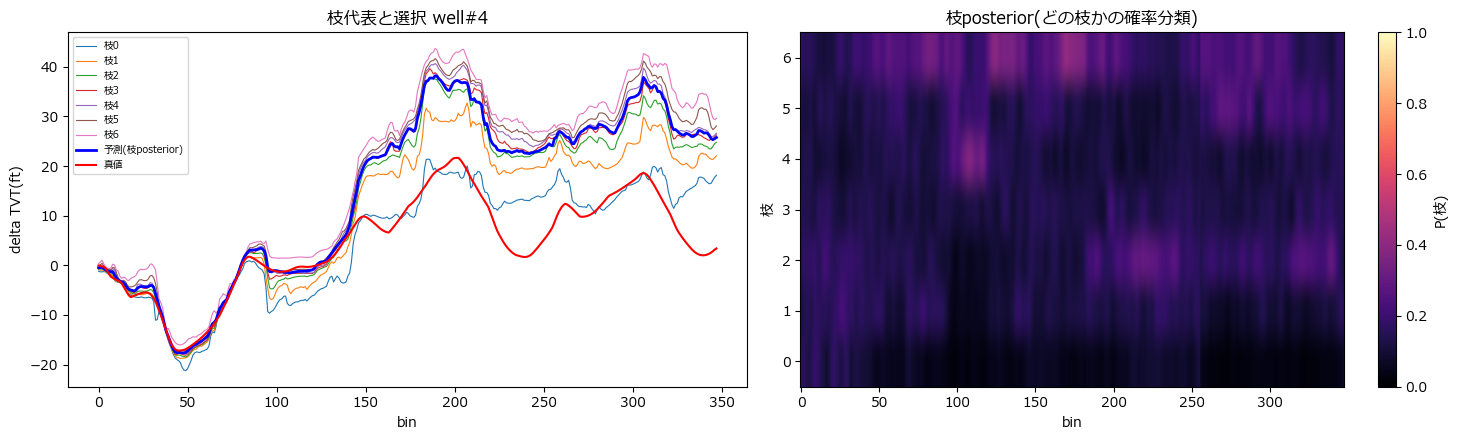

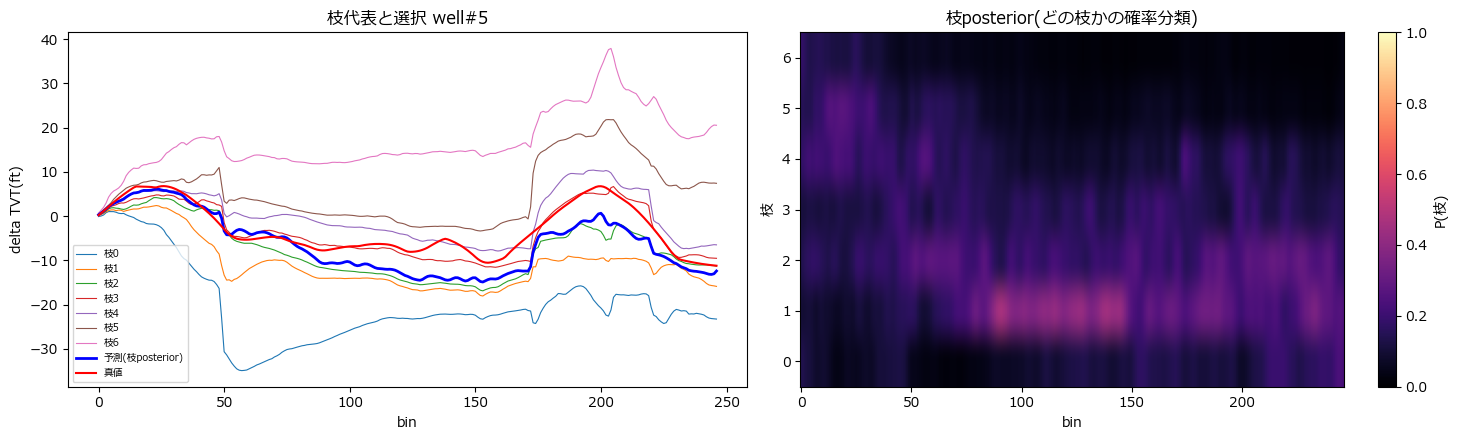

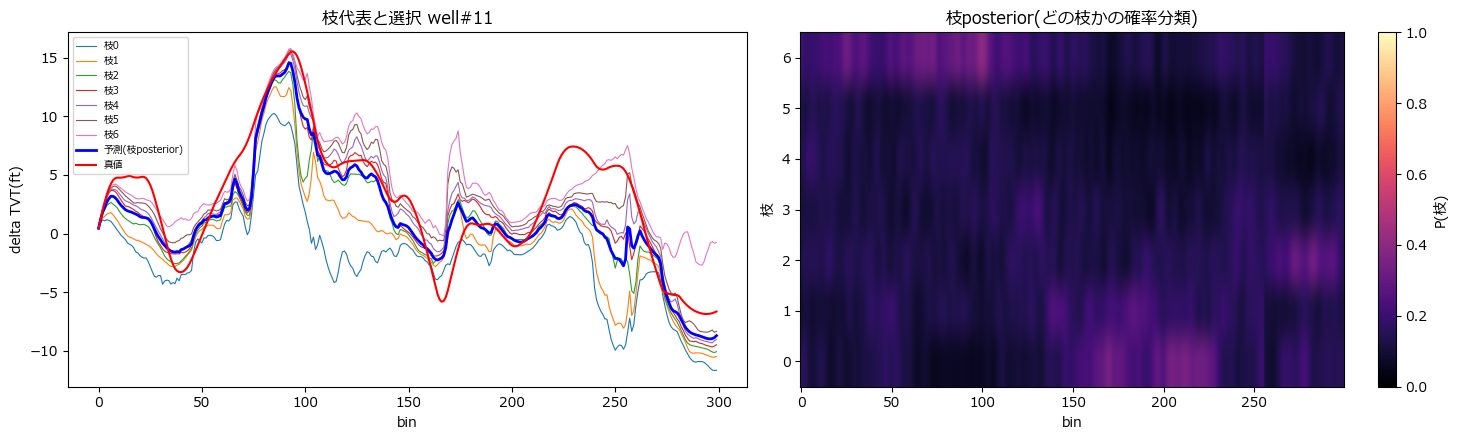

saved viz.


: 

In [ ]:
# ===== 評価 + モード可視化 =====
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
plt.rcParams["font.family"]="Meiryo"
m=np.isfinite(oof)
def rmse(a): e=(a-y)[m]; return float(np.sqrt(np.mean(e*e)))
def sg(delta):
    tvt=lk+delta; out=tvt.copy(); oidx=np.argsort(g,kind="stable"); gs=g[oidx]; bd=np.flatnonzero(np.diff(gs))+1
    for rows in np.split(oidx,bd):
        rr=rows[m[rows]]
        if len(rr)<5: continue
        rr=rr[np.argsort(mds[rr])]; v=tvt[rr]; wl=min(17,len(v)); wl-=(wl%2==0)
        if wl>=5: out[rr]=savgol_filter(v,wl,3)
    return float(np.sqrt(np.mean(((out-(lk+y))[m])**2)))
print("=== v47 潜在モードHMM OOF 行レベル overall RMSE ===")
print(f"  soft(枝posterior)   raw={rmse(oof):.4f}  +SG={sg(oof):.4f}")
print(f"  Viterbi(枝commit)   raw={rmse(oof_v):.4f}  +SG={sg(oof_v):.4f}")
print(f"  参考 mean候補={np.sqrt(np.mean((DEL.mean(1)-y)[m]**2)):.4f}  K={K}天井(oracle-mode)={orc_mode:.4f}")

# 例示: fold0 val 坑井の枝posterior + 予測
enc=Enc(FEATD,K).to(DEV); crf=StickyCRF(K).to(DEV); enc.load_state_dict(torch.load(ART/"mode_enc0.pt")); crf.load_state_dict(torch.load(ART/"mode_crf0.pt")); enc.eval(); crf.eval()
_,va0=folds[0]; vw=list(dict.fromkeys(CHW[list(va0)]))[:3]
for wid in vw:
    chs=[i for i in va0 if CHW[i]==wid]; REP=[]; YB=[]; PP=[]
    with torch.no_grad():
        for i in chs:
            b=SEQ[i]; feat=torch.from_numpy(b["feat"])[None].to(DEV); rep=torch.from_numpy(b["rep"])[None].to(DEV); mask=torch.ones(1,len(b["rep"]),device=DEV)
            with torch.autocast("cuda",enabled=USE_AMP): em=enc(feat,mask==0)
            PP.append(crf.marg(em.float(),rep,mask)[0].cpu().numpy()); REP.append(b["rep"]); YB.append(b["ybin"])
    rep=np.concatenate(REP); yb=np.concatenate(YB); P=np.concatenate(PP); pr=(P*rep).sum(1); x=np.arange(len(rep))
    fig,ax=plt.subplots(1,2,figsize=(15,4.5))
    for k in range(K): ax[0].plot(x,rep[:,k],lw=0.8,label=f"枝{k}")
    ax[0].plot(x,pr,"b",lw=2,label="予測(枝posterior)"); ax[0].plot(x,yb,"r",lw=1.5,label="真値")
    ax[0].legend(fontsize=7); ax[0].set_xlabel("bin"); ax[0].set_ylabel("delta TVT(ft)"); ax[0].set_title(f"枝代表と選択 well#{wid}")
    im=ax[1].imshow(P.T,aspect="auto",origin="lower",cmap="magma",vmin=0,vmax=1); plt.colorbar(im,ax=ax[1],label="P(枝)")
    ax[1].set_yticks(range(K)); ax[1].set_ylabel("枝"); ax[1].set_xlabel("bin"); ax[1].set_title("枝posterior(どの枝かの確率分類)")
    plt.tight_layout(); plt.savefig(ART/f"v47_mode_well{wid}.png",dpi=110); plt.show()
print("saved viz.")
